In [25]:
from utils import load_splits
import torch
import pandas as pd

In [26]:
#global random seed
SEED = 42
torch.manual_seed(SEED)

In [27]:
X_train, X_val, X_test, y_train, y_val, y_test = load_splits()

1
2
3


In [28]:
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

True
NVIDIA GeForce RTX 3050 6GB Laptop GPU


device(type='cuda')

In [29]:
import glob
import json
from pathlib import Path
logs = {}
for file in Path("logs").glob("*json"):
    with open(file, "r", encoding = "utf-8") as f:
        logs[f.name[5:-5]] = json.load(f)
        

In [30]:
logs

{'logistic_regression': {'eval_loss': 0.2568609844891156,
  'eval_accuracy': 0.892960462873674,
  'eval_precision_macro': 0.8789118921521425,
  'eval_recall_macro': 0.8803954666023631,
  'eval_f1_macro': 0.8796530538489339},
 'distilbert-base-uncased_lr_5e-06': [{'epoch': 1.0,
   'grad_norm': 0.8381789326667786,
   'learning_rate': 5e-06,
   'loss': 0.988840540936008,
   'step': 2723,
   'eval_accuracy': 0.9320690024643737,
   'eval_f1_macro': 0.9314470067208123,
   'eval_loss': 0.1868487447500229,
   'eval_precision_macro': 0.9303597759154798,
   'eval_recall_macro': 0.9330282202338269,
   'eval_runtime': 33.5583,
   'eval_samples_per_second': 278.113,
   'eval_steps_per_second': 69.551},
  {'epoch': 2.0,
   'grad_norm': 112.81194305419922,
   'learning_rate': 5e-06,
   'loss': 0.6910685056979894,
   'step': 5446,
   'eval_accuracy': 0.9381763634415515,
   'eval_f1_macro': 0.9373868756677177,
   'eval_loss': 0.20731845498085022,
   'eval_precision_macro': 0.937483712775464,
   'eval_r

In [52]:
val_metrics = []
for k, log in logs.items():
    if isinstance(log, list):
        for epoch in log:
            epoch["model"] = f"{k[:10]}"
            val_metrics.append(epoch)
            #val_metrics[f"{k}_epoch_{epoch["epoch"]:.0f}"] = epoch
    else:
        val_metrics.append(log)
        log["model"] = "tfidf"


In [53]:
val = pd.DataFrame(val_metrics)

val = val.sort_values("model").reset_index(drop=True)

val = val.drop(columns=["grad_norm", "step", "eval_runtime", "eval_samples_per_second", "eval_steps_per_second"])

val

,eval_loss,eval_accuracy,eval_precision_macro,eval_recall_macro,eval_f1_macro,model,epoch,learning_rate,loss
0,0.186849,0.932069,0.930360,0.933028,0.931447,distilbert,1.0,0.000005,0.988841
1,0.207318,0.938176,0.937484,0.937292,0.937387,distilbert,2.0,0.000005,0.691069
2,0.240233,0.941284,0.940800,0.940233,0.940509,distilbert,3.0,0.000005,0.611688
3,0.252824,0.939248,0.938239,0.938836,0.938528,distilbert,4.0,0.000005,0.545515
4,0.269540,0.941069,0.940753,0.939823,0.940268,distilbert,5.0,0.000005,0.474234
5,0.190280,0.941176,0.939489,0.942407,0.940654,distilbert,1.0,0.000030,0.838175
6,0.255323,0.944284,0.943680,0.943464,0.943571,distilbert,2.0,0.000030,0.554565
7,0.332534,0.944927,0.943411,0.945685,0.944387,distilbert,3.0,0.000030,0.306288
8,0.405262,0.942355,0.942102,0.941076,0.941565,distilbert,4.0,0.000030,0.156991
9,0.483982,0.942891,0.942525,0.941751,0.942124,distilbert,5.0,0.000030,0.058826


In [68]:
val["display_name"] = (
    "lr_" + val["learning_rate"].map(lambda x: format(x, ".0e"))
    + "_e_" + val["epoch"].astype("Int64").astype(str)
).fillna("baseline")
val["display_name"]

0     lr_5e-06_e_1
1     lr_5e-06_e_2
2     lr_5e-06_e_3
3     lr_5e-06_e_4
4     lr_5e-06_e_5
5     lr_3e-05_e_1
6     lr_3e-05_e_2
7     lr_3e-05_e_3
8     lr_3e-05_e_4
9     lr_3e-05_e_5
10    lr_2e-05_e_1
11    lr_2e-05_e_2
12    lr_2e-05_e_3
13    lr_2e-05_e_4
14    lr_2e-05_e_5
15    lr_1e-05_e_1
16    lr_1e-05_e_2
17    lr_1e-05_e_3
18    lr_1e-05_e_4
19    lr_1e-05_e_5
20    lr_1e-06_e_1
21    lr_1e-06_e_2
22    lr_1e-06_e_3
23    lr_1e-06_e_4
24    lr_1e-06_e_5
25        baseline
Name: display_name, dtype: str

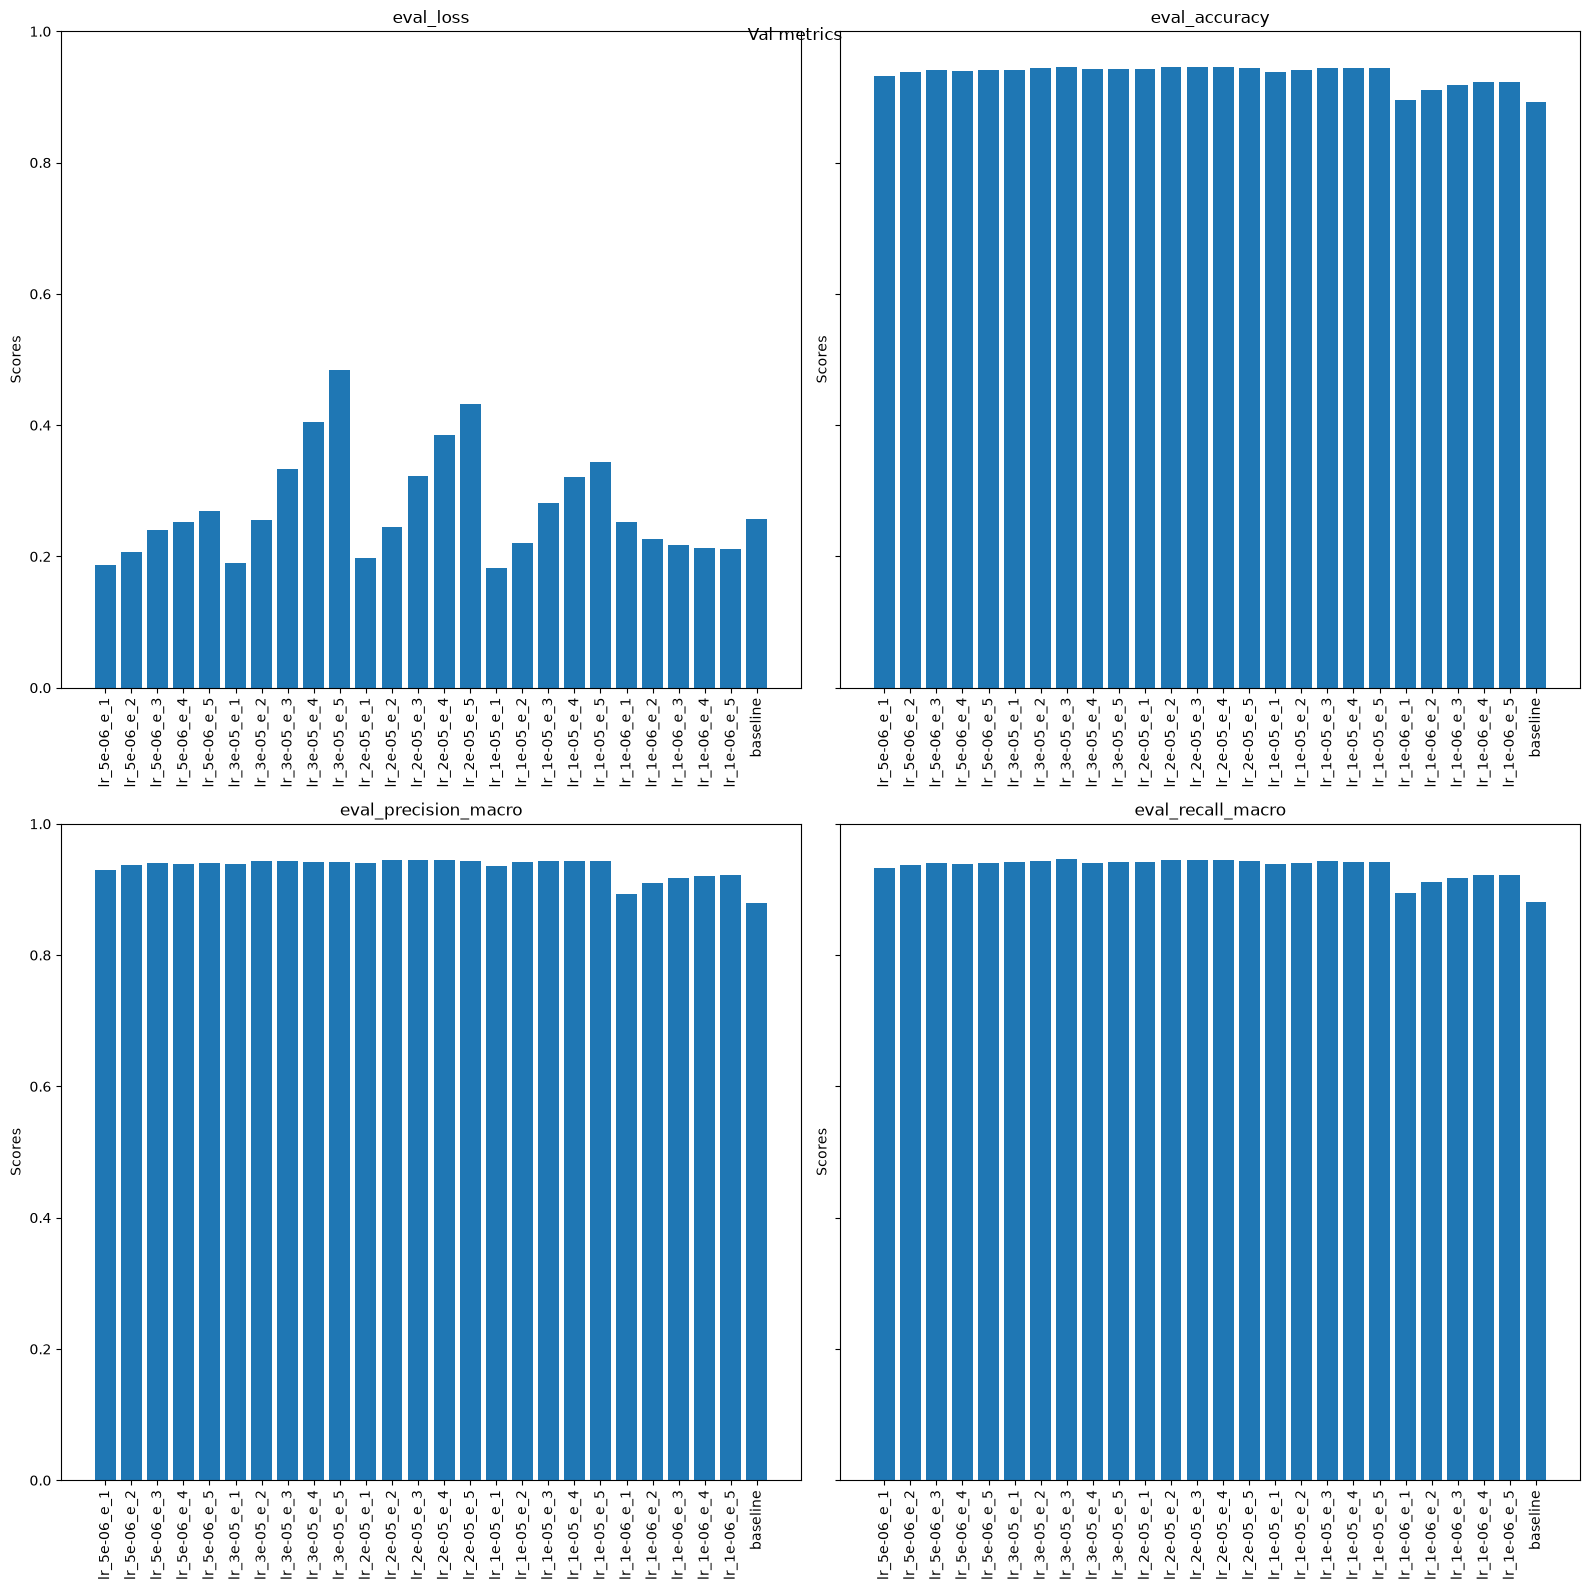

In [71]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2,2, figsize = (16,16), sharey = True)

metrics = ['eval_loss', 'eval_accuracy', 'eval_precision_macro', 'eval_recall_macro']


for index, metric in enumerate(metrics):
    i = index // 2
    j = index % 2

    axes[i, j].bar(val["display_name"], val[metric])
    axes[i,j].set_title(metric)
    axes[i,j].set_ylim(0,1)
    axes[i,j].set_ylabel('Scores')
    axes[i,j].tick_params(axis="x", labelrotation=90)
plt.tight_layout()
fig.suptitle("Val metrics")
plt.show()



In [72]:
val[val["eval_loss"]==val["eval_loss"].min()]

,eval_loss,eval_accuracy,eval_precision_macro,eval_recall_macro,eval_f1_macro,model,epoch,learning_rate,loss,display_name
15,0.181904,0.938069,0.936457,0.938886,0.937479,distilbert,1.0,0.00001,0.896604,lr_1e-05_e_1


In [73]:
val[val["eval_f1_macro"]==val["eval_f1_macro"].max()]

,eval_loss,eval_accuracy,eval_precision_macro,eval_recall_macro,eval_f1_macro,model,epoch,learning_rate,loss,display_name
12,0.322631,0.945677,0.945373,0.944548,0.944945,distilbert,3.0,0.00002,0.340316,lr_2e-05_e_3


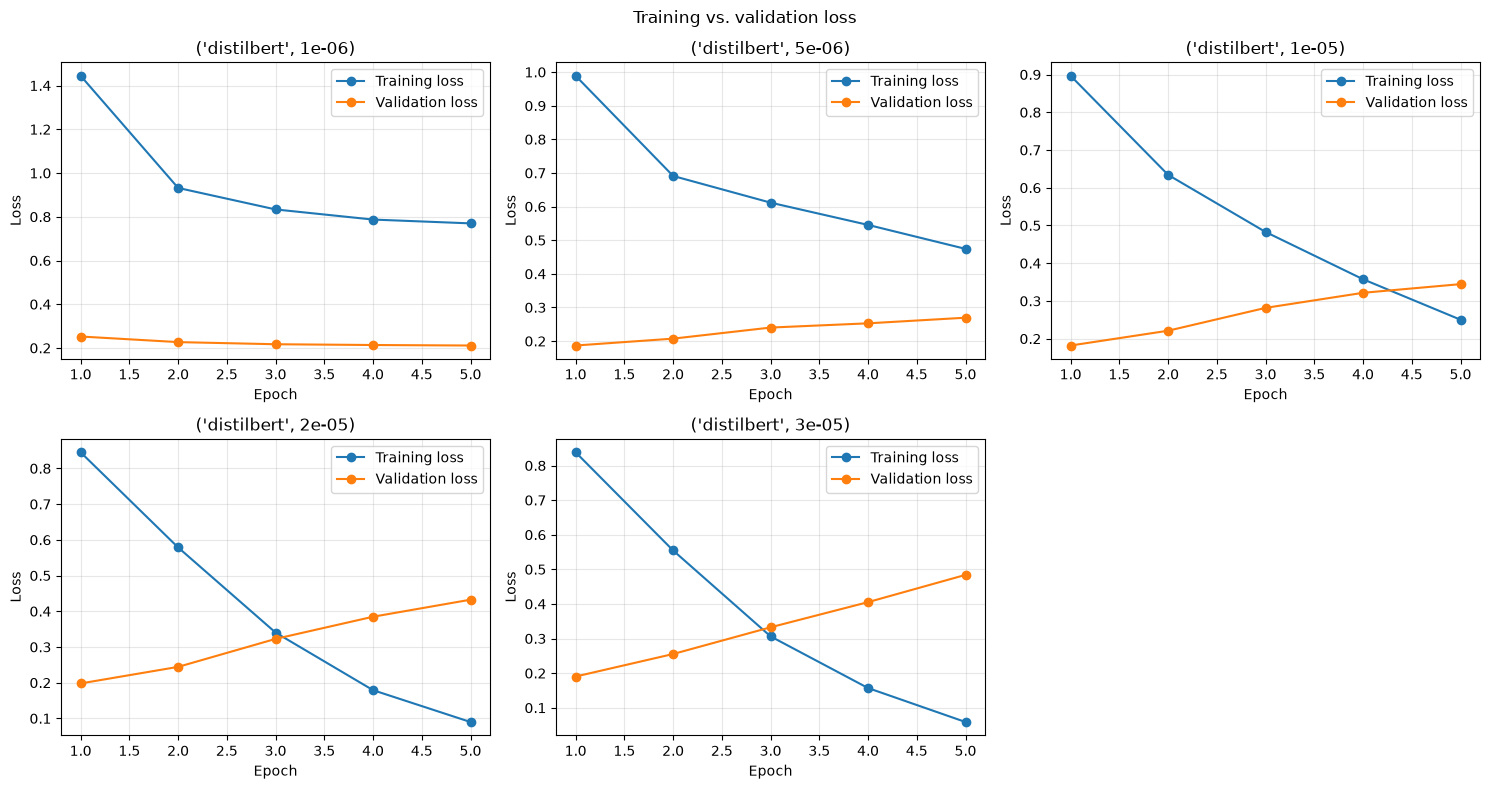

In [74]:
loss_val = val.dropna(subset=["loss", "eval_loss"]).copy()
loss_val = loss_val.sort_values(["model", "epoch"])

groups = list(loss_val.groupby(["model", "learning_rate"], sort=True))
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for ax, (model_name, group) in zip(axes, groups):
    ax.plot(group["epoch"], group["loss"], marker="o", label="Training loss")
    ax.plot(group["epoch"], group["eval_loss"], marker="o", label="Validation loss")
    ax.set_title(model_name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(alpha=0.3)
    ax.legend()

for ax in axes[len(groups):]:
    ax.set_visible(False)

fig.suptitle("Training vs. validation loss")
plt.tight_layout()
plt.show()


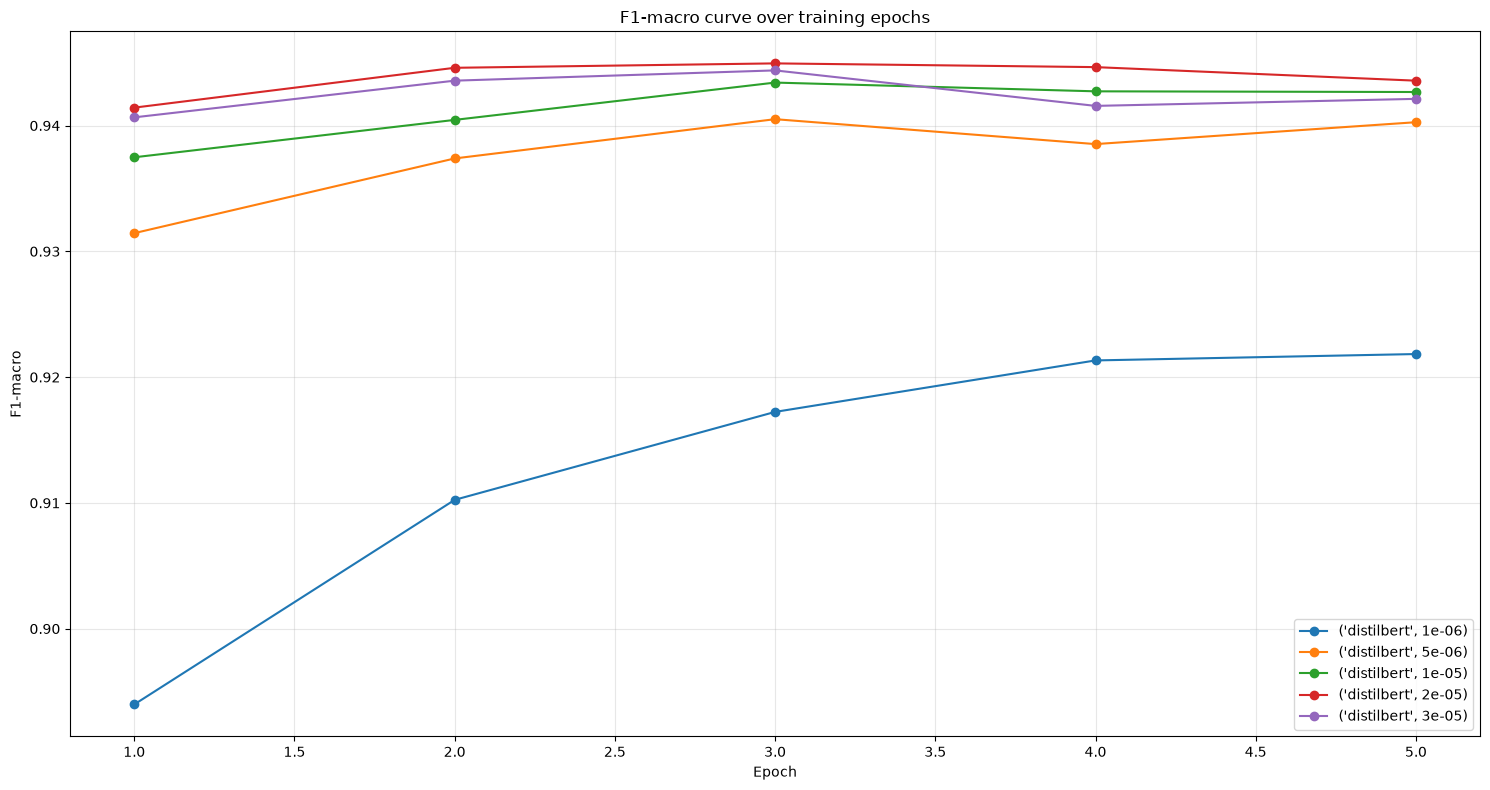

In [85]:
f1_macro_val = val.dropna(subset=["loss", "eval_loss"]).copy()
f1_macro_val = f1_macro_val.sort_values(["model", "epoch"])

groups = list(f1_macro_val.groupby(["model", "learning_rate"], sort=True))
fig, ax = plt.subplots(figsize=(15, 8))


for (model_name, group) in groups:
    ax.plot(group["epoch"], group["eval_f1_macro"], marker="o", label=f"{model_name}")
ax.set_title('F1-macro curve over training epochs')
ax.set_xlabel("Epoch")
ax.set_ylabel("F1-macro")
ax.grid(alpha=0.3)
ax.legend()

for ax in axes[len(groups):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()